In [1]:
!pip install yfinance 

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 855.3 kB/s eta 0:00:02
   ---------- ----------------------------- 0.5/2.0 MB 855.3 kB/s eta 0:00:02
   ---------- ----------------------------- 0.5/2.0 MB 855.3 kB/s eta 0:00:02
   --------------- ------------------------ 0.8/2.0 MB 605.5 kB/s eta 0:00:02
   --------------- ------------------------ 0.8/2.0 MB 605.5 kB/s eta 0:00:02
   --------------- ------------------------ 0.8/2.0 MB 605.5 kB/s eta 0:00:02
   --------------------- ------------------ 1.0/2.0 MB 530.1 kB/s eta 0:00:02
   --------------------- ------------------ 1.0/2.0 MB 530.1 kB/s eta 0:00:02
   -------------------------- ------------- 1.3/2.0 MB 516.1 kB/s eta 0:00:02
   -------------------------- ------------- 1.3/2.0 MB 516.1 kB/s eta 0:00:02
   ----------

In [3]:
!pip install torch

In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [105]:
ticker = 'MSFT'#stock data from companies
df = yf.download(ticker,'2021-01-01')

[*********************100%***********************]  1 of 1 completed


In [106]:
df

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2021-01-04,207.565353,212.628386,204.819296,212.180244,37130100
2021-01-05,207.765625,208.356799,205.667948,207.155392,23823000
2021-01-06,202.378418,206.421224,202.082838,202.302137,35930700
2021-01-07,208.137497,209.138665,203.770522,204.085161,27694500
2021-01-08,209.405624,210.320982,206.936087,208.509341,22956200
...,...,...,...,...,...
2026-10-12,541.150024,542.739990,535.700012,537.530029,18314900
2026-10-13,543.450012,551.150024,543.059998,544.640015,23852000


<Axes: xlabel='Date'>

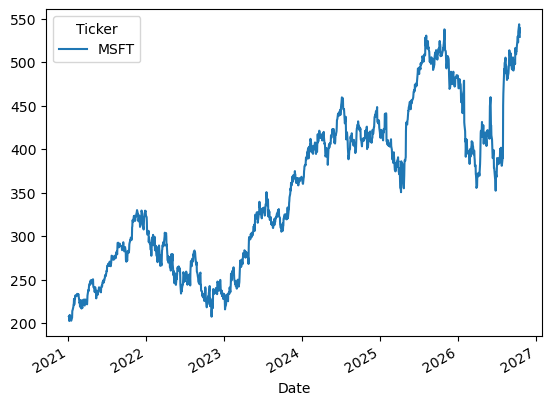

In [107]:
df.Close.plot()

In [108]:
scaler = StandardScaler()

df['Close'] = scaler.fit_transform(df['Close'])

In [109]:
df.Close

Ticker,MSFT
Date,
2021-01-04,-1.611358
2021-01-05,-1.609144
2021-01-06,-1.668700
2021-01-07,-1.605033
2021-01-08,-1.591014
...,...
2026-10-12,2.076427
2026-10-13,2.101853
2026-10-14,1.993956


In [110]:
seq_length =  30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

In [111]:
data

array([[[-1.61135822],
        [-1.60914421],
        [-1.66869989],
        ...,
        [-1.32886297],
        [-1.32359203],
        [-1.33719034]],

       [[-1.60914421],
        [-1.66869989],
        [-1.60503316],
        ...,
        [-1.32359203],
        [-1.33719034],
        [-1.32599143]],

       [[-1.66869989],
        [-1.60503316],
        [-1.59101399],
        ...,
        [-1.33719034],
        [-1.32599143],
        [-1.33032278]],

       ...,

       [[ 1.6327884 ],
        [ 1.58635752],
        [ 1.73338914],
        ...,
        [ 2.009212  ],
        [ 2.0764267 ],
        [ 2.10185311]],

       [[ 1.58635752],
        [ 1.73338914],
        [ 1.61819603],
        ...,
        [ 2.0764267 ],
        [ 2.10185311],
        [ 1.99395602]],

       [[ 1.73338914],
        [ 1.61819603],
        [ 1.55462967],
        ...,
        [ 2.10185311],
        [ 1.99395602],
        [ 2.05752238]]])

In [112]:
train_size = int(0.8*len(data))

X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

In [113]:
class PredictionModel(nn.Module):

    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc= nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)

        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])

        return out

In [114]:
model = PredictionModel(input_dim=1, hidden_dim = 32, num_layers=2, output_dim =1).to(device)

In [115]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [116]:
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, y_train)

    if i % 25 == 0:
        print(i, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 0.8723046779632568
25 0.019927315413951874
50 0.006228501442819834
75 0.005174180492758751
100 0.004836143460124731
125 0.00461468705907464
150 0.004417073912918568
175 0.004227773752063513


In [117]:
model.eval()

y_test_pred = model(X_test)

y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())

In [118]:
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])

In [119]:
train_rmse

5.7577948570251465

In [120]:
test_rmse

9.858060836791992

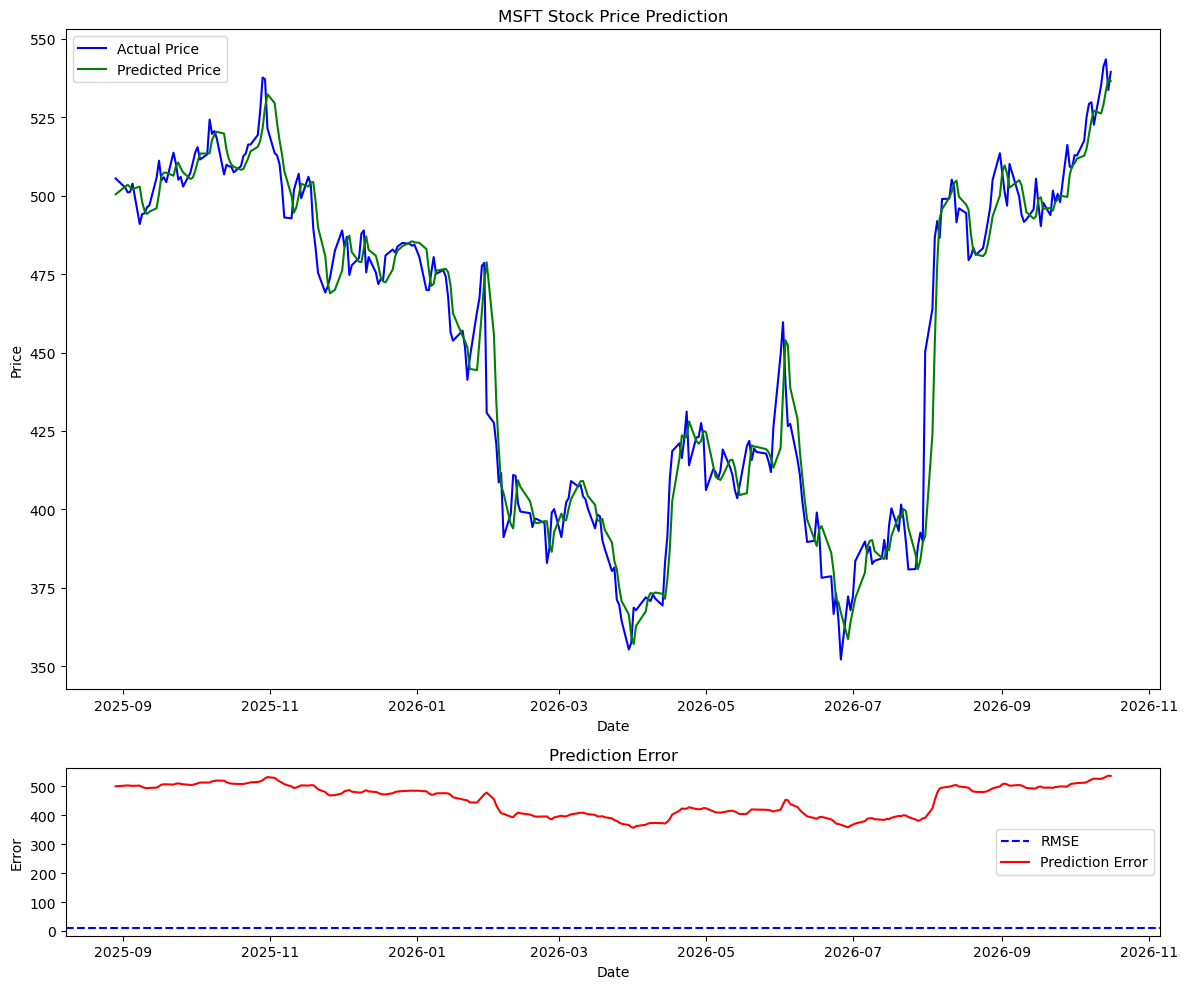

In [121]:
fig = plt.figure(figsize=(12,10))

gs = fig.add_gridspec(4,1)

ax1 = fig.add_subplot(gs[:3,0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color = 'blue', label = 'Actual Price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color = 'green', label = 'Predicted Price')
ax1.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel('Date')
plt.ylabel('Price')

ax2 = fig.add_subplot(gs[3,0])
ax2.axhline(test_rmse, color = 'blue', linestyle= '--', label='RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test_pred), 'r', label = 'Prediction Error')
ax2.legend()
plt.title("Prediction Error")
plt.xlabel('Date')
plt.ylabel('Error')

plt.tight_layout()
plt.show()